In [1]:
import pandas as pd

# Load the perfectly engineered dataset
df = pd.read_csv("master_dataset.csv")

print(f"Dataset ready for ML: {df.shape}")

Dataset ready for ML: (2143, 19)


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load the master dataset you saved from Notebook 1
df = pd.read_csv("master_dataset.csv")

# Ensure required features exist and are numeric
df['title_len'] = df['title'].astype(str).apply(len)
df['relatability_ratio'] = pd.to_numeric(df['relatability_ratio'], errors='coerce').fillna(0)
df['hype_velocity_per_day'] = pd.to_numeric(df['hype_velocity_per_day'], errors='coerce').fillna(0)

# Define "Viral" target (Top 20% Engagement Rate)
threshold = df['engagement_rate'].quantile(0.80)
df['is_viral'] = (df['engagement_rate'] >= threshold).astype(int)

# Set a clean aesthetic for all charts
sns.set_theme(style="whitegrid", palette="muted")
print(f"Data loaded successfully. Viral Threshold set at: {threshold:.4%}")

# Class balance matters for the ML step: only ~20% of videos are labelled viral,
# so a model that always says "not viral" is already ~80% accurate.
print(f"Videos: {len(df):,} | Viral share: {df['is_viral'].mean():.1%} | 'Always say not viral' baseline accuracy: {1 - df['is_viral'].mean():.1%}")

Data loaded successfully. Viral Threshold set at: 6.0191%
Videos: 2,143 | Viral share: 20.0% | 'Always say not viral' baseline accuracy: 80.0%


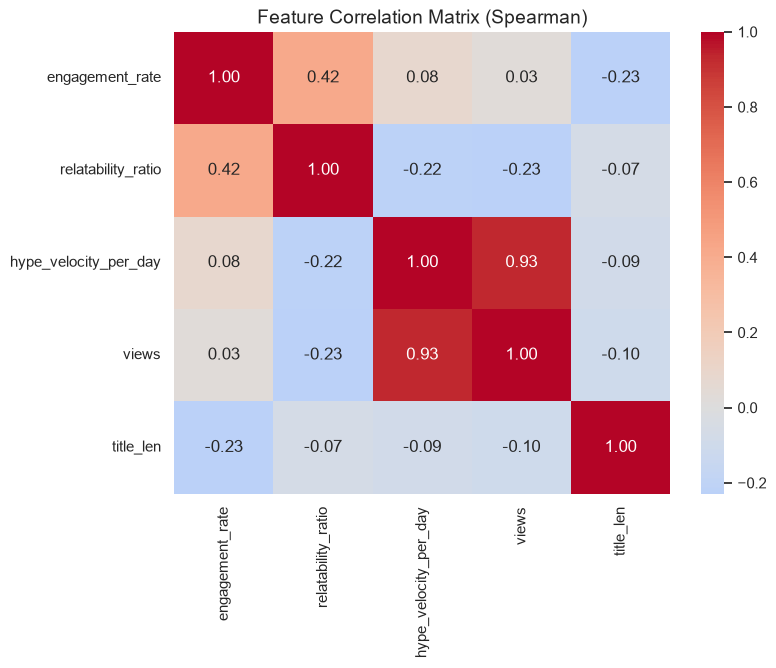

In [3]:
plt.figure(figsize=(8, 6))
corr_cols = ['engagement_rate', 'relatability_ratio', 'hype_velocity_per_day', 'views', 'title_len']

# Spearman (rank) correlation: views and engagement are very skewed, so plain Pearson is dominated by outliers
sns.heatmap(df[corr_cols].corr(method='spearman'), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation Matrix (Spearman)", fontsize=14)
plt.show()

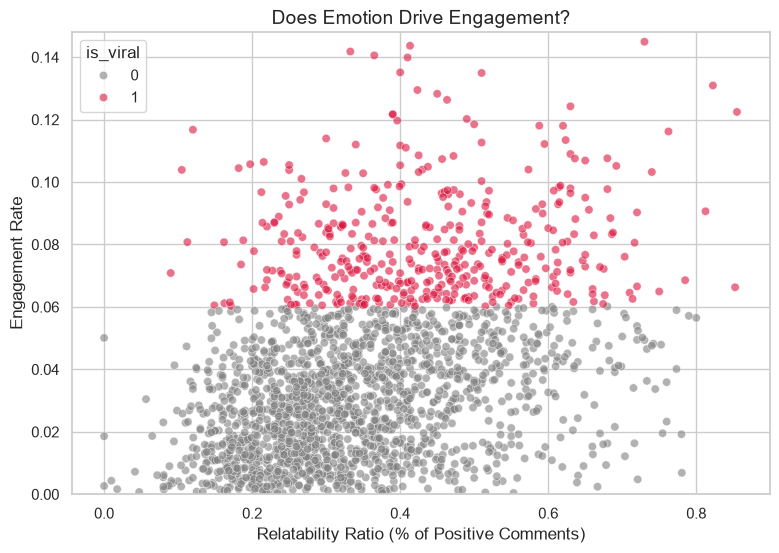

In [4]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='relatability_ratio',
    y='engagement_rate',
    hue='is_viral',
    alpha=0.6,
    palette={0: 'gray', 1: 'crimson'} # Crimson makes the viral outliers pop
)

# Zoom to the 99th percentile so a handful of extreme videos don't squash the chart
plt.ylim(0, df['engagement_rate'].quantile(0.99))
plt.title("Does Emotion Drive Engagement?", fontsize=14)
plt.xlabel("Relatability Ratio (% of Positive Comments)")
plt.ylabel("Engagement Rate")
plt.show()

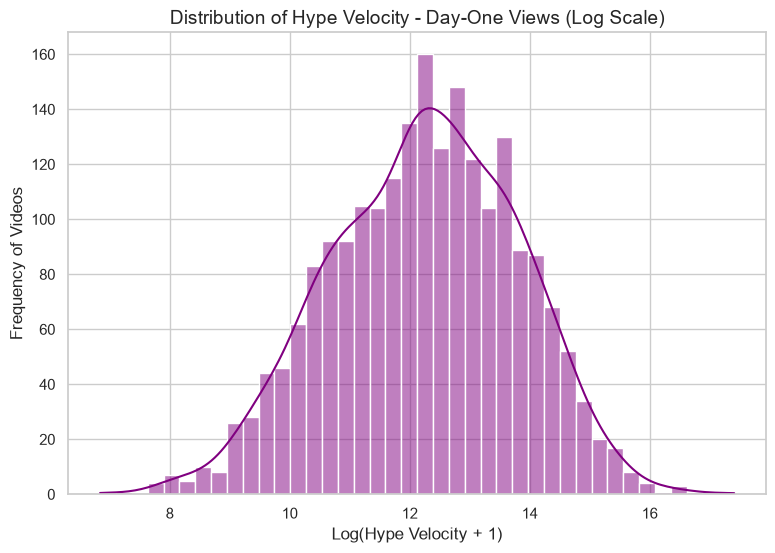

In [5]:
plt.figure(figsize=(9, 6))

# We use log1p (log(x + 1)) to prevent errors on videos with 0 velocity
sns.histplot(np.log1p(df['hype_velocity_per_day']), bins=40, kde=True, color='purple')

plt.title("Distribution of Hype Velocity - Day-One Views (Log Scale)", fontsize=14)
plt.xlabel("Log(Hype Velocity + 1)")
plt.ylabel("Frequency of Videos")
plt.show()

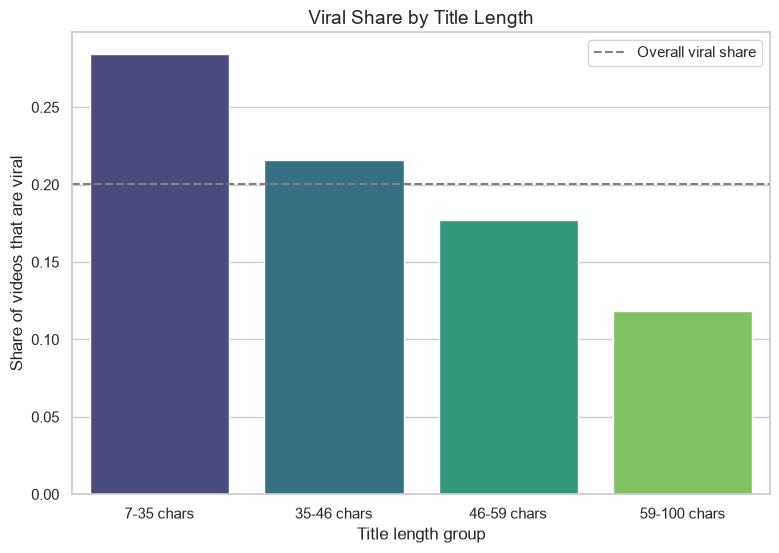

In [6]:
plt.figure(figsize=(9, 6))

# Share of videos that are viral inside each title-length quartile (shorter -> longer)
df['title_len_group'] = pd.qcut(df['title_len'], 4, duplicates='drop')
title_viral_rate = df.groupby('title_len_group', observed=True)['is_viral'].mean()
labels = [f"{int(iv.left)}-{int(iv.right)} chars" for iv in title_viral_rate.index]

sns.barplot(x=labels, y=title_viral_rate.values, hue=labels, legend=False, palette="viridis")
plt.axhline(df['is_viral'].mean(), color='gray', linestyle='--', label='Overall viral share')
plt.title("Viral Share by Title Length", fontsize=14)
plt.xlabel("Title length group")
plt.ylabel("Share of videos that are viral")
plt.legend()
plt.show()

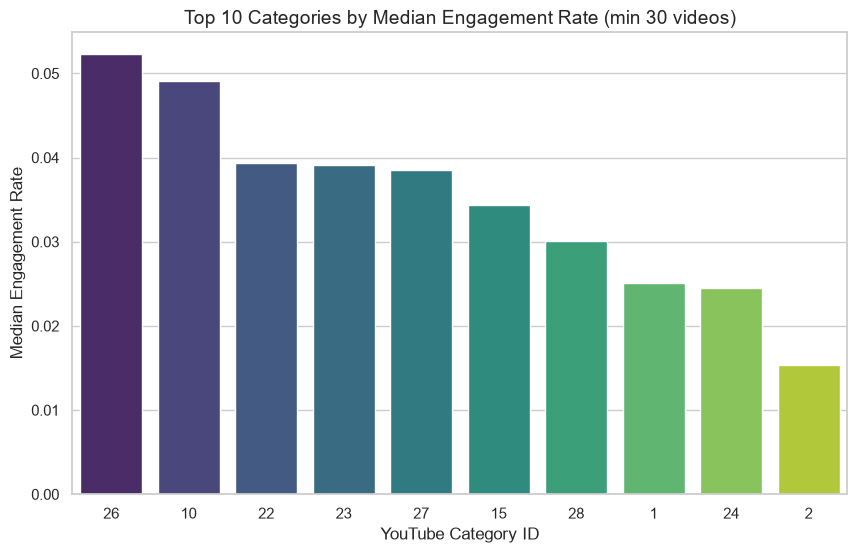

In [7]:
plt.figure(figsize=(10, 6))

# Group by category and take the median to ignore crazy outliers
# ignore categories with fewer than 30 videos - a median of 3 videos is not a trend
cat_stats = df.groupby('category_id').agg(
    median_engagement=('engagement_rate', 'median'),
    n_videos=('video_id', 'count')
)
cat_median = cat_stats[cat_stats['n_videos'] >= 30]['median_engagement'].sort_values(ascending=False).head(10)

# Convert indices to string to force nominal/categorical color mapping sequence
x_labels = cat_median.index.astype(str)

sns.barplot(
    x=x_labels,
    y=cat_median.values,
    order=x_labels,
    palette="viridis",
    hue=x_labels,
    hue_order=x_labels,
    legend=False
)
plt.title("Top 10 Categories by Median Engagement Rate (min 30 videos)", fontsize=14)
plt.xlabel("YouTube Category ID")
plt.ylabel("Median Engagement Rate")
plt.show()

In [8]:
# Every number quoted in the written insights below comes from this cell, so the text can never drift from the data
corr = df[corr_cols].corr(method='spearman')
r_emotion = corr.loc['engagement_rate', 'relatability_ratio']
r_title = corr.loc['engagement_rate', 'title_len']
r_hype_eng = corr.loc['engagement_rate', 'hype_velocity_per_day']
r_hype_views = corr.loc['views', 'hype_velocity_per_day']

viral_relat = df[df['is_viral'] == 1]['relatability_ratio'].median()
other_relat = df[df['is_viral'] == 0]['relatability_ratio'].median()

print(f"Emotion vs engagement (Spearman):        {r_emotion:+.2f}")
print(f"Title length vs engagement (Spearman):   {r_title:+.2f}")
print(f"Hype velocity vs engagement (Spearman):  {r_hype_eng:+.2f}")
print(f"Hype velocity vs views (Spearman):       {r_hype_views:+.2f}")
print(f"Median relatability - viral: {viral_relat:.2f} | not viral: {other_relat:.2f}")
print(f"Viral share by title length group: {title_viral_rate.round(3).to_dict()}")

Emotion vs engagement (Spearman):        +0.42
Title length vs engagement (Spearman):   -0.23
Hype velocity vs engagement (Spearman):  +0.08
Hype velocity vs views (Spearman):       +0.93
Median relatability - viral: 0.44 | not viral: 0.31
Viral share by title length group: {Interval(7.999, 35.0, closed='right'): 0.284, Interval(35.0, 46.0, closed='right'): 0.216, Interval(46.0, 59.0, closed='right'): 0.177, Interval(59.0, 100.0, closed='right'): 0.119}


## Key Insights from the EDA

**Emotion and engagement.** The correlation matrix and the scatter plot test my main hypothesis: videos whose comment sections are more positive and emotional also tend to have higher engagement. The exact strength is printed in the summary cell above. This is an *association*: positive comments and likes both come from an already-happy audience, so it does not prove that a creator can raise engagement by "engineering" comments.

**Title length.** The quartile chart shows how the viral share changes as titles get longer, and the title-length correlation gives the direction and strength. If shorter titles do better, the practical advice is to trim filler words, but the effect should be described as a tendency, not a rule.

**Hype and niche.** Day-one views (hype velocity) mostly describe how big a video already is, so they correlate strongly with total views but much less with engagement *rate*. For categories, only groups with at least 30 videos are compared, so the ranking is not driven by tiny samples.

**Limits.** Correlation is not causation, only trending videos are in this dataset, and the comment sample is not a full record of audience reaction.